# Öğrenci Geçer mi? — Students Performance in Exams

**Amaç:** Öğrencinin demografik ve arka plan bilgilerine bakarak sınavı **geçip geçmeyeceğini** (evet / hayır) tahmin eden bir sınıflandırma modeli kurmak.

**Veri seti:** Kaggle — *Students Performance in Exams* (1000 öğrenci, 8 sütun)

**Kullanılan kütüphaneler:** pandas, numpy, matplotlib, seaborn, scikit-learn

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4.5)
pd.set_option("display.max_columns", None)

## 1. Veriyi Tanıma

In [2]:
df = pd.read_csv("data/StudentsPerformance.csv")
print("Boyut (satır, sütun):", df.shape)
df.head()

Boyut (satır, sütun): (1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 103.5 KB


In [4]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


### Sütunların açıklaması

| Sütun | Tür | Açıklama |
|---|---|---|
| `gender` | Kategorik | Öğrencinin cinsiyeti (female / male) |
| `race/ethnicity` | Kategorik | Etnik grup (group A–E, anonimleştirilmiş) |
| `parental level of education` | Kategorik (sıralı) | Öğrencinin **ebeveyninin (anne/babasının)** en yüksek eğitim düzeyi (lise terk → yüksek lisans). Öğrencinin kendi eğitim düzeyi değildir. |
| `lunch` | Kategorik | Öğle yemeği türü: *standard* (ücretli) veya *free/reduced* (ücretsiz/indirimli). Veri ABD okul sistemine göre hazırlanmıştır; ABD'de ücretsiz/indirimli okul yemeği **düşük gelirli ailelerin** çocuklarına verilir. Bu sütun aslında yemeği değil, **ailenin gelir düzeyini** dolaylı olarak gösterir. |
| `test preparation course` | Kategorik | Sınava hazırlık kursunu tamamladı mı (completed / none) |
| `math score` | Sayısal (0–100) | Matematik sınav notu |
| `reading score` | Sayısal (0–100) | Okuma sınav notu |
| `writing score` | Sayısal (0–100) | Yazma sınav notu |

In [5]:
for col in df.columns[:5]:
    print(f"{col}: {df[col].unique().tolist()}")

gender: ['female', 'male']
race/ethnicity: ['group B', 'group C', 'group A', 'group D', 'group E']
parental level of education: ["bachelor's degree", 'some college', "master's degree", "associate's degree", 'high school', 'some high school']
lunch: ['standard', 'free/reduced']
test preparation course: ['none', 'completed']


### Hedef değişkenin oluşturulması

Veri setinde hazır bir "geçti/kaldı" sütunu yok. Bu yüzden hedefi üç sınavın ortalamasından türetiyoruz:

- **ortalama = (math + reading + writing) / 3**
- **ortalama ≥ 60 → geçti = 1 ("evet")**, aksi halde **0 ("hayır")**

#### Neden 60?

Veri setinde resmi bir geçme notu yok; eşiği biz belirledik. Veri **ABD okul sistemine** göre hazırlanmış
(öğle yemeği sütunu da ABD'deki ücretsiz okul yemeği programına dayanıyor). ABD'de yaygın kullanılan not sisteminde
60'ın altı **F**, yani "kaldı" anlamına gelir. Bu yüzden verinin geldiği sistemdeki geçme sınırını, yani 60'ı kullandık:

| Not | Harf notu | Anlamı |
|---|---|---|
| 90–100 | A | Geçti |
| 80–89 | B | Geçti |
| 70–79 | C | Geçti |
| 60–69 | D | Geçti (en düşük geçer not) |
| **0–59** | **F** | **Kaldı** |

In [6]:
df["ortalama"] = df[["math score", "reading score", "writing score"]].mean(axis=1)
df["gecti"] = (df["ortalama"] >= 60).astype(int)

sayim = df["gecti"].value_counts().rename({1: "Evet (geçti)", 0: "Hayır (kaldı)"})
oran = df["gecti"].value_counts(normalize=True).rename({1: "Evet (geçti)", 0: "Hayır (kaldı)"})
pd.DataFrame({"Öğrenci sayısı": sayim, "Oran (%)": (oran * 100).round(1)})

,Öğrenci sayısı,Oran (%)
gecti,,
Evet (geçti),715,71.5
Hayır (kaldı),285,28.5


**Sınıflar dengeli mi?** 1000 öğrencinin **715'i "evet" (geçti, %71.5)**, **285'i "hayır" (kaldı, %28.5)**.
Sınıflar **tam dengeli değil**: geçenler yaklaşık 2.5 kat fazla. Aşırı bir dengesizlik değil ama önemli bir sonucu var:
hiçbir şey öğrenmeden herkese "geçer" diyen bir model bile %71.5 accuracy alır. Bu yüzden modeli değerlendirirken
yalnızca accuracy'ye değil, **precision, recall ve confusion matrix**'e de bakacağız. Train/test ayrımında da
`stratify` kullanarak bu oranı iki tarafta da koruyacağız.

## 2. Veri Temizleme

### 2.1 Eksik değerler ve tekrar eden satırlar

In [7]:
print("Sütun bazında eksik değer sayısı:")
print(df.isnull().sum())
print("\nTekrar eden satır sayısı:", df.duplicated().sum())

Sütun bazında eksik değer sayısı:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
ortalama                       0
gecti                          0
dtype: int64

Tekrar eden satır sayısı: 0


Veri setinde **hiç eksik değer ve tekrar eden satır yok**. Bu yüzden doldurma (imputation) veya satır silme işlemine gerek kalmadı.

### 2.2 Gereksiz sütunlar (veri sızıntısını önleme)

Hedefimiz (`gecti`) doğrudan `math score`, `reading score`, `writing score` ve `ortalama` sütunlarından hesaplandı.
Bu sütunları modele girdi olarak verirsek model cevabı "görmüş" olur ve %100'e yakın, ama **anlamsız** bir başarı elde eder
(buna *veri sızıntısı / data leakage* denir). Asıl soru: *Sınav notlarını bilmeden, öğrencinin arka planına bakarak geçip geçmeyeceğini tahmin edebilir miyiz?*

Bu yüzden not sütunlarını ve `ortalama` sütununu **model girdisinden çıkarıyoruz**. Bunlar sadece hedefi oluşturmak ve grafiklerde kullanılacak.

In [8]:
not_sutunlari = ["math score", "reading score", "writing score", "ortalama"]
X_ham = df.drop(columns=not_sutunlari + ["gecti"])
y = df["gecti"]
X_ham.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course
0,female,group B,bachelor's degree,standard,none
1,female,group C,some college,standard,completed
2,female,group B,master's degree,standard,none
3,male,group A,associate's degree,free/reduced,none
4,male,group C,some college,standard,none


### 2.3 Kategorik dönüşüm

Makine öğrenmesi modelleri metinle çalışamaz, sayılara ihtiyaç duyar. Tüm özelliklerimiz kategorik olduğu için
**one-hot encoding** (`pd.get_dummies`) uyguluyoruz: her kategori 0/1 değerli ayrı bir sütun olur.
`drop_first=True` ile her özellikten bir kategoriyi (referans kategori) atıyoruz; çünkü diğer sütunlar 0 ise o kategori zaten belli olur
(gereksiz tekrar ve çoklu doğrusal bağlantının önüne geçer).

In [9]:
X = pd.get_dummies(X_ham, drop_first=True).astype(int)
print("Dönüşüm sonrası boyut:", X.shape)
X.head()

Dönüşüm sonrası boyut: (1000, 12)


,gender_male,race/ethnicity_group B,race/ethnicity_group C,race/ethnicity_group D,race/ethnicity_group E,parental level of education_bachelor's degree,parental level of education_high school,parental level of education_master's degree,parental level of education_some college,parental level of education_some high school,lunch_standard,test preparation course_none
0,0,1,0,0,0,1,0,0,0,0,1,1
1,0,0,1,0,0,0,0,0,1,0,1,0
2,0,1,0,0,0,0,0,1,0,0,1,1
3,1,0,0,0,0,0,0,0,0,0,0,1
4,1,0,1,0,0,0,0,0,1,0,1,1


## 3. Görselleştirme

Her grafikte bir özelliğin **geçme oranına** etkisine bakıyoruz. Kesikli çizgi tüm öğrencilerin genel geçme oranını (%71.5) gösterir.

In [10]:
genel_oran = df["gecti"].mean()

def gecme_orani_grafigi(sutun, baslik, sira=None, ax=None):
    oranlar = df.groupby(sutun)["gecti"].mean()
    if sira is not None:
        oranlar = oranlar.reindex(sira)
    ax = ax or plt.gca()
    sns.barplot(x=oranlar.index, y=oranlar.values * 100, ax=ax, color="#4C72B0")
    ax.axhline(genel_oran * 100, ls="--", color="gray", label=f"Genel oran (%{genel_oran*100:.1f})")
    for i, v in enumerate(oranlar.values):
        ax.text(i, v * 100 + 1, f"%{v*100:.1f}", ha="center")
    ax.set_ylim(0, 100)
    ax.set_ylabel("Geçme oranı (%)")
    ax.set_xlabel("")
    ax.set_title(baslik)
    ax.legend(loc="lower right")

### Grafik 1 — Sınıf dağılımı (Geçti / Kaldı)

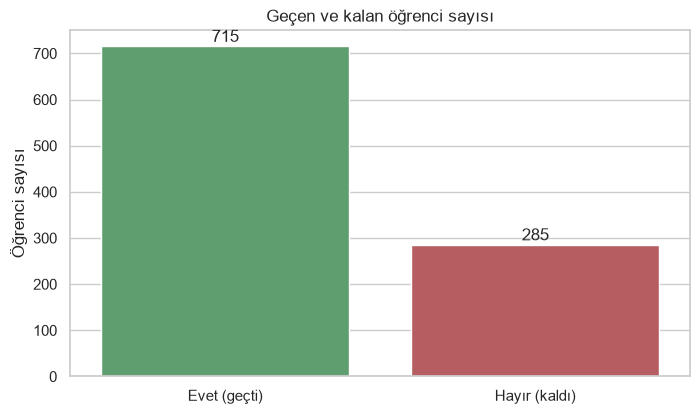

In [11]:
ax = sns.countplot(x=df["gecti"].map({1: "Evet (geçti)", 0: "Hayır (kaldı)"}),
                   order=["Evet (geçti)", "Hayır (kaldı)"], palette=["#55A868", "#C44E52"], hue=df["gecti"].map({1: "Evet (geçti)", 0: "Hayır (kaldı)"}), legend=False)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height() + 10), ha="center")
ax.set_xlabel("")
ax.set_ylabel("Öğrenci sayısı")
ax.set_title("Geçen ve kalan öğrenci sayısı")
plt.show()

**Yorum:** Öğrencilerin çoğu (715) geçmiş, 285'i kalmış. "Hayır" sınıfı azınlıkta olduğu için model bu sınıfı öğrenmekte
zorlanabilir; bu yüzden modelde `class_weight="balanced"` kullanarak azınlık sınıfa daha fazla önem vereceğiz.

### Grafik 2 — Cinsiyete göre geçme oranı

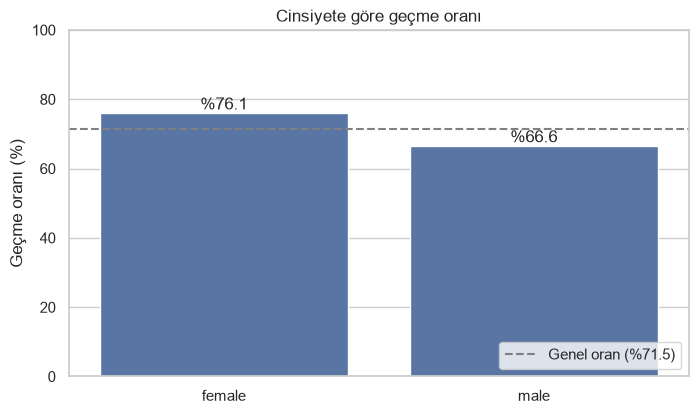

In [12]:
gecme_orani_grafigi("gender", "Cinsiyete göre geçme oranı")
plt.show()

**Yorum:** Kız öğrencilerin geçme oranı (%76.1) erkeklerden (%66.6) yaklaşık 10 puan daha yüksek. Kızlar okuma (72.6'ya karşı 65.5)
ve yazma (72.5'e karşı 63.3) sınavlarında belirgin şekilde daha başarılı; erkekler ise matematikte önde (68.7'ye karşı 63.6).
İki dersteki üstünlük, kızların üç ders ortalamasını yükseltiyor. Cinsiyet, sonucu etkileyen anlamlı bir özellik.

### Grafik 3 — Öğle yemeği türüne göre geçme oranı

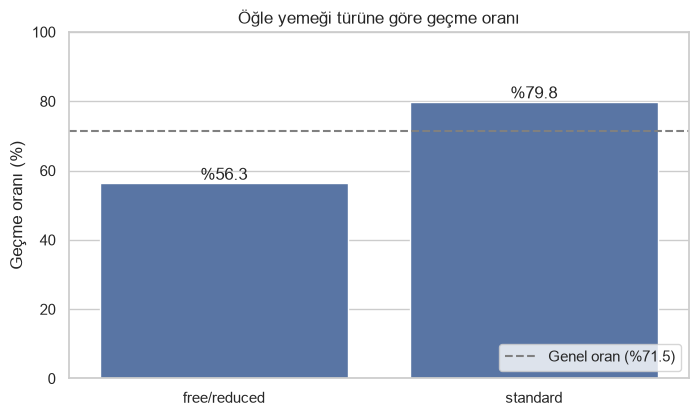

In [13]:
gecme_orani_grafigi("lunch", "Öğle yemeği türüne göre geçme oranı")
plt.show()

**Yorum:** En büyük farkı yaratan özelliklerden biri. Standart yemek alan öğrencilerin geçme oranı %79.8 iken
ücretsiz/indirimli yemek alanlarda %56.3'e düşüyor (~23 puan fark). Ücretsiz/indirimli yemek, ailenin düşük gelirli
olduğunun dolaylı bir göstergesi; sosyoekonomik durum başarıyı güçlü şekilde etkiliyor.

### Grafik 4 — Sınava hazırlık kursuna göre geçme oranı

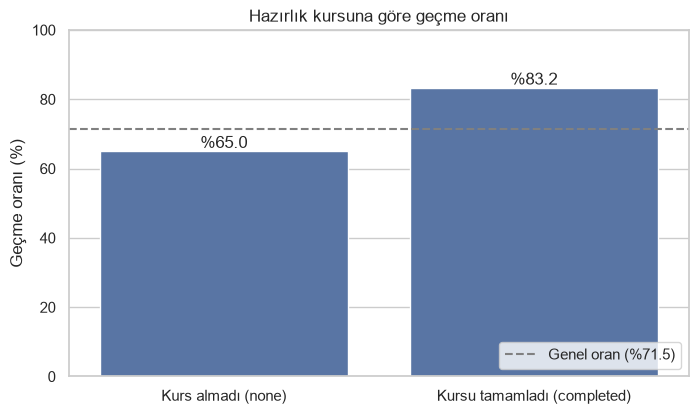

In [14]:
gecme_orani_grafigi("test preparation course", "Hazırlık kursuna göre geçme oranı", sira=["none", "completed"])
plt.gca().set_xticks([0, 1], ["Kurs almadı (none)", "Kursu tamamladı (completed)"])
plt.show()

**Yorum:** Hazırlık kursunu tamamlayanların geçme oranı %83.2, tamamlamayanların %65.0 (~18 puan fark). Kurs, öğrencinin
kontrol edebildiği ve başarıyı belirgin şekilde artıran bir faktör olarak öne çıkıyor.

### Grafik 5 — Ebeveynin (anne/baba) eğitim düzeyine göre geçme oranı

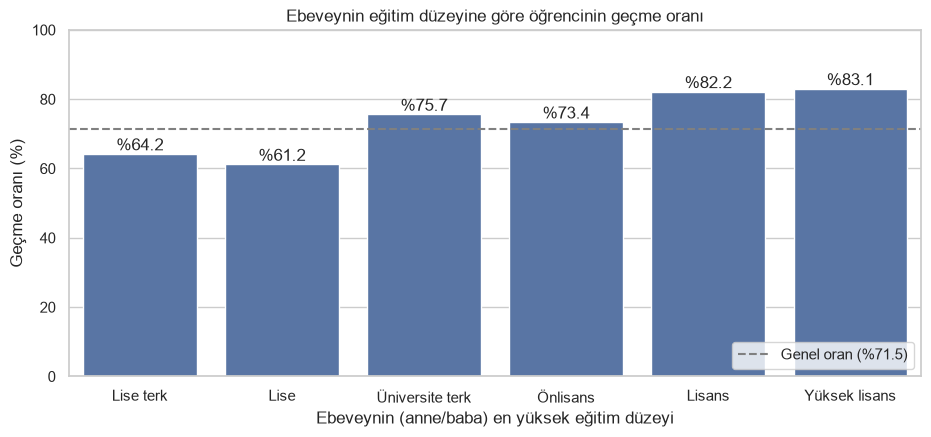

In [15]:
egitim_sirasi = ["some high school", "high school", "some college",
                 "associate's degree", "bachelor's degree", "master's degree"]
egitim_turkce = ["Lise terk", "Lise", "Üniversite terk", "Önlisans", "Lisans", "Yüksek lisans"]
plt.figure(figsize=(11, 4.5))
gecme_orani_grafigi("parental level of education", "Ebeveynin eğitim düzeyine göre öğrencinin geçme oranı", sira=egitim_sirasi)
plt.gca().set_xticks(range(6), egitim_turkce)
plt.xlabel("Ebeveynin (anne/baba) en yüksek eğitim düzeyi")
plt.show()

**Not:** Bu sütun **öğrencinin değil, ebeveyninin** eğitim düzeyini gösterir (veri setindeki adı: *parental level of education*).

**Yorum:** Ebeveynin eğitim düzeyi arttıkça öğrencinin geçme oranı genel olarak artıyor: ebeveyni lise ve altı olanlarda oran
%61–64 civarındayken, lisans ve yüksek lisans mezunu ebeveynlerde %82–83'e çıkıyor. Eğitimli ailelerin çocuklarına daha
fazla akademik destek sağlayabildiği düşünülebilir.

### Grafik 6 — Etnik gruba göre geçme oranı

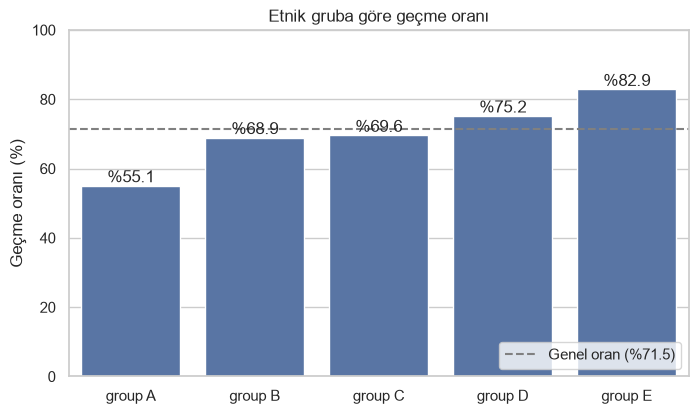

In [16]:
gecme_orani_grafigi("race/ethnicity", "Etnik gruba göre geçme oranı",
                    sira=["group A", "group B", "group C", "group D", "group E"])
plt.show()

**Yorum:** Gruplar arasında belirgin bir sıralama var: group A'da geçme oranı %55.1 iken group E'de %82.9. Grupların
gerçek karşılığı veri setinde gizlendiği için neden konusunda yorum yapmak zor; ancak bu özellik de modele bilgi taşıyor.

## 4. Model

### 4.1 Train / Test ayrımı
Verinin %80'i modeli eğitmek (train), %20'si modeli test etmek için ayrıldı. `stratify=y` ile her iki kümede de geçti/kaldı oranı korunuyor;
`random_state=42` sonuçların tekrarlanabilir olmasını sağlıyor.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Train kümesi:", X_train.shape, " Test kümesi:", X_test.shape)
print("Train kümesinde geçme oranı: %.3f | Test kümesinde geçme oranı: %.3f" % (y_train.mean(), y_test.mean()))

Train kümesi: (800, 12)  Test kümesi: (200, 12)
Train kümesinde geçme oranı: 0.715 | Test kümesinde geçme oranı: 0.715


### 4.2 Modeller
İki sınıflandırma modeli kuruyoruz:

1. **Logistic Regression** — basit, yorumlanabilir; her özelliğin etkisini katsayılarla gösterir.
2. **Decision Tree** — "eğer ... ise" kurallarıyla karar verir. Ezberlemeyi (overfitting) önlemek için derinliği `max_depth=4` ile sınırlandırıldı.

Her iki modelde de `class_weight="balanced"` kullanıldı: azınlıktaki "kaldı" sınıfının hataları daha ağır cezalandırılır.
Bu, bölüm 5'te tartışacağımız gibi, **kalacak öğrenciyi kaçırmamak** için önemli.

In [18]:
modeller = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42),
}
tahminler = {}
for ad, model in modeller.items():
    model.fit(X_train, y_train)
    tahminler[ad] = model.predict(X_test)
    print(f"{ad} eğitildi.")

Logistic Regression eğitildi.
Decision Tree eğitildi.


## 5. Sonuç

### 5.1 Accuracy, Precision, Recall

In [19]:
satirlar = []
for ad, y_pred in tahminler.items():
    satirlar.append({
        "Model": ad,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (geçti)": precision_score(y_test, y_pred, pos_label=1),
        "Recall (geçti)": recall_score(y_test, y_pred, pos_label=1),
        "Precision (kaldı)": precision_score(y_test, y_pred, pos_label=0),
        "Recall (kaldı)": recall_score(y_test, y_pred, pos_label=0),
        "F1 (geçti)": f1_score(y_test, y_pred, pos_label=1),
    })

# Karşılaştırma için referans: herkese "geçer" diyen, hiçbir şey öğrenmeyen model
satirlar.append({"Model": "Referans: herkese 'geçer' de",
                 "Accuracy": y_test.mean(), "Precision (geçti)": y_test.mean(), "Recall (geçti)": 1.0,
                 "Precision (kaldı)": np.nan, "Recall (kaldı)": 0.0,
                 "F1 (geçti)": 2 * y_test.mean() / (1 + y_test.mean())})
sonuclar = pd.DataFrame(satirlar).set_index("Model").round(3)
sonuclar

,Accuracy,Precision (geçti),Recall (geçti),Precision (kaldı),Recall (kaldı),F1 (geçti)
Model,,,,,,
Logistic Regression,0.630,0.795,0.65,0.398,0.579,0.715
Decision Tree,0.580,0.776,0.58,0.355,0.579,0.664
Referans: herkese 'geçer' de,0.715,0.715,1.00,NaN,0.000,0.834


**Metriklerin anlamı** (pozitif sınıf = "geçti"):
- **Accuracy:** Tüm tahminlerin yüzde kaçı doğru.
- **Precision:** Model "geçer" dediklerinin yüzde kaçı gerçekten geçti.
- **Recall:** Gerçekten geçenlerin yüzde kaçını model yakalayabildi. *(Kaldı sınıfı için de aynı şekilde ayrıca hesaplandı.)*

**Yorum:** İki model kalan öğrencileri yakalamada eşit (kaldı recall'u ikisinde de 0.579), diğer bütün metriklerde ise
Logistic Regression daha iyi (accuracy 0.63'e karşı 0.58). Bu yüzden **ana modelimiz Logistic Regression**.

Dikkat edilmesi gereken bir nokta: Herkese "geçer" diyen referans modelin accuracy'si (0.715) bizim modellerimizden yüksek görünüyor.
Ama bu model **kalacak 57 öğrencinin hiçbirini tespit edemiyor** (kaldı recall'u = 0). Bizim modelimiz ise `class_weight="balanced"`
sayesinde kalacak öğrencilerin **%57.9'unu** yakalıyor. Bu problemde amaç risk altındaki öğrenciyi bulmak olduğu için
accuracy'den bir miktar fedakârlık etmek bilinçli bir tercih (bkz. 5.4).

Genel başarının çok yüksek olmamasının sebebi, modelin **sınav notlarını görmeden** sadece 5 arka plan bilgisiyle tahmin yapması.
Aynı arka plana sahip iki öğrenciden biri çalışıp geçerken diğeri kalabiliyor; bu bilgiler sonucu tek başına belirlemiyor.

In [20]:
for ad, y_pred in tahminler.items():
    print("=" * 60)
    print(ad)
    print(classification_report(y_test, y_pred, target_names=["Hayır (kaldı)", "Evet (geçti)"], digits=3))

Logistic Regression
               precision    recall  f1-score   support

Hayır (kaldı)      0.398     0.579     0.471        57
 Evet (geçti)      0.795     0.650     0.715       143

     accuracy                          0.630       200
    macro avg      0.596     0.615     0.593       200
 weighted avg      0.682     0.630     0.646       200

Decision Tree
               precision    recall  f1-score   support

Hayır (kaldı)      0.355     0.579     0.440        57
 Evet (geçti)      0.776     0.580     0.664       143

     accuracy                          0.580       200
    macro avg      0.565     0.580     0.552       200
 weighted avg      0.656     0.580     0.600       200



### 5.2 Confusion Matrix

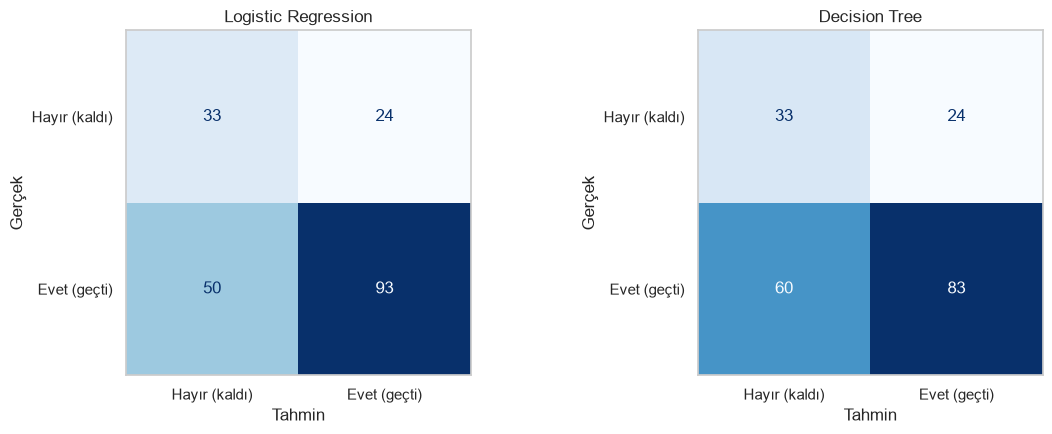

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (ad, y_pred) in zip(axes, tahminler.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=["Hayır (kaldı)", "Evet (geçti)"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(ad)
    ax.grid(False)
    ax.set_xlabel("Tahmin")
    ax.set_ylabel("Gerçek")
plt.tight_layout()
plt.show()

**Confusion matrix nasıl okunur?** Satırlar gerçek durumu, sütunlar modelin tahminini gösterir (test kümesi: 57 kalan, 143 geçen öğrenci).

| | Logistic Regression | Decision Tree |
|---|---|---|
| Kaldı → doğru "kalır" dedi (doğru hayır) | 33 | 33 |
| Kaldı → yanlışlıkla **"geçer" dedi (yanlış evet)** | **24** | **24** |
| Geçti → yanlışlıkla **"kalır" dedi (yanlış hayır)** | **50** | **60** |
| Geçti → doğru "geçer" dedi (doğru evet) | 93 | 83 |

**Yorum:** İki model kalan öğrencilerde aynı sonucu veriyor (57 öğrenciden 33'ünü yakalıyor). Fark, geçen öğrencilerde ortaya çıkıyor:
Decision Tree geçen 10 öğrenciye daha yanlışlıkla "kalır" diyor. Logistic Regression bu yüzden daha başarılı.
Her iki modelde de yanlış "hayır" sayısı yüksek; çünkü `class_weight="balanced"` modeli şüpheli durumlarda "kalır" demeye yönlendiriyor.
Bunun neden kabul edilebilir bir bedel olduğunu 5.4'te açıklıyoruz.

### 5.3 Hangi özellikler daha etkili? (Logistic Regression katsayıları)

**Katsayı nedir?** Logistic Regression her özelliğe bir sayı (katsayı) verir. Bu sayı, o özelliğin öğrencinin
**geçme şansını ne yönde ve ne kadar** etkilediğini gösterir:

- **Pozitif katsayı (+)** → geçme şansını **artırır**
- **Negatif katsayı (−)** → geçme şansını **azaltır**
- **Sıfırdan uzaklık** → etkinin **gücü** (sayı ne kadar büyükse etki o kadar güçlü)

**Neye göre?** Kategorik dönüşümde (bölüm 2.3) her özellikten bir kategoriyi atmıştık (`drop_first=True`).
Atılan kategori **karşılaştırma noktası (referans)** oldu. Her katsayı, öğrenciyi bu referansla karşılaştırır:

| Özellik | Referans (karşılaştırılan) kategori |
|---|---|
| Cinsiyet | Kız |
| Etnik grup | Grup A |
| Ebeveyn eğitimi | Önlisans (associate's degree) |
| Öğle yemeği | Ücretsiz/indirimli |
| Hazırlık kursu | Kursu tamamladı |

Örneğin "Erkek" katsayısı, erkek öğrencinin, diğer her şeyi aynı olan bir **kız** öğrenciye göre geçme şansının ne kadar farklı olduğunu söyler.

**"Kaç kat?" yorumu:** Katsayının kendisi (log-odds) sezgisel değil. Onu `e^katsayı` ile **kat oranına** (odds ratio) çevirince anlaşılır hale gelir:
- 1'den büyükse → geçme şansı o kadar **kat artar** (ör. 2.0 = 2 kat)
- 1'den küçükse → geçme şansı **azalır** (ör. 0.5 = yarıya iner)

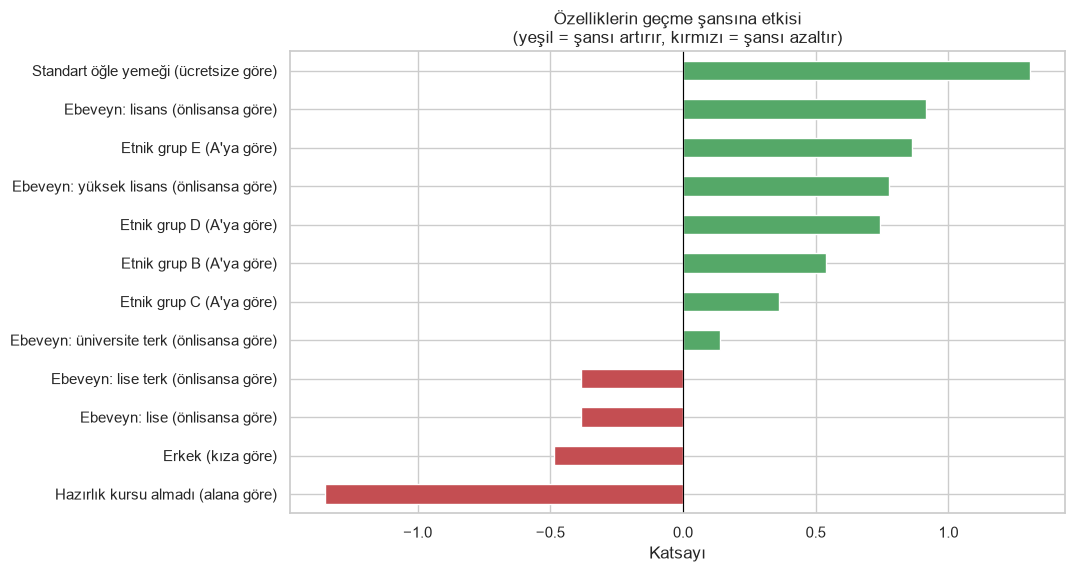

,Katsayı,Kat oranı (e^katsayı),Anlamı
Standart öğle yemeği (ücretsize göre),1.31,3.70,Geçme şansı 3.7 kat artar
Ebeveyn: lisans (önlisansa göre),0.92,2.50,Geçme şansı 2.5 kat artar
Etnik grup E (A'ya göre),0.86,2.37,Geçme şansı 2.4 kat artar
Ebeveyn: yüksek lisans (önlisansa göre),0.78,2.18,Geçme şansı 2.2 kat artar
Etnik grup D (A'ya göre),0.74,2.10,Geçme şansı 2.1 kat artar
Etnik grup B (A'ya göre),0.54,1.72,Geçme şansı 1.7 kat artar
Etnik grup C (A'ya göre),0.36,1.44,Geçme şansı 1.4 kat artar
Ebeveyn: üniversite terk (önlisansa göre),0.14,1.15,Geçme şansı 1.2 kat artar
Ebeveyn: lise (önlisansa göre),-0.38,0.68,Geçme şansı %32 azalır
Ebeveyn: lise terk (önlisansa göre),-0.38,0.68,Geçme şansı %32 azalır


In [22]:
turkce_adlar = {
    "gender_male": "Erkek (kıza göre)",
    "race/ethnicity_group B": "Etnik grup B (A'ya göre)",
    "race/ethnicity_group C": "Etnik grup C (A'ya göre)",
    "race/ethnicity_group D": "Etnik grup D (A'ya göre)",
    "race/ethnicity_group E": "Etnik grup E (A'ya göre)",
    "parental level of education_bachelor's degree": "Ebeveyn: lisans (önlisansa göre)",
    "parental level of education_high school": "Ebeveyn: lise (önlisansa göre)",
    "parental level of education_master's degree": "Ebeveyn: yüksek lisans (önlisansa göre)",
    "parental level of education_some college": "Ebeveyn: üniversite terk (önlisansa göre)",
    "parental level of education_some high school": "Ebeveyn: lise terk (önlisansa göre)",
    "lunch_standard": "Standart öğle yemeği (ücretsize göre)",
    "test preparation course_none": "Hazırlık kursu almadı (alana göre)",
}
katsayilar = pd.Series(modeller["Logistic Regression"].coef_[0], index=X.columns).rename(index=turkce_adlar).sort_values()

plt.figure(figsize=(10, 6))
katsayilar.plot(kind="barh", color=np.where(katsayilar > 0, "#55A868", "#C44E52"))
plt.axvline(0, color="black", lw=0.8)
plt.title("Özelliklerin geçme şansına etkisi\n(yeşil = şansı artırır, kırmızı = şansı azaltır)")
plt.xlabel("Katsayı")
plt.show()

kat = np.exp(katsayilar)
tablo = pd.DataFrame({
    "Katsayı": katsayilar.round(2),
    "Kat oranı (e^katsayı)": kat.round(2),
    "Anlamı": [f"Geçme şansı {k:.1f} kat artar" if k >= 1 else f"Geçme şansı %{(1 - k) * 100:.0f} azalır" for k in kat],
}).sort_values("Katsayı", ascending=False)
tablo

**Yorum:** Model, grafiklerde gördüğümüz ilişkileri sayılarla doğrulamış:

- **En olumlu etki: standart öğle yemeği.** Standart yemek alan öğrencinin geçme şansı, ücretsiz/indirimli yemek alana göre yaklaşık **3.7 kat** fazla.
  Bu, ailenin maddi durumunun başarı üzerinde ne kadar etkili olduğunu gösteriyor.
- **En olumsuz etki: hazırlık kursu almamak.** Kursu almayan öğrencinin geçme şansı, alana göre yaklaşık **%74 daha düşük**.
- **Ebeveyn eğitimi:** Ebeveyni lisans veya yüksek lisans mezunu olan öğrencinin şansı, önlisans mezunu ebeveyne göre **2 katın üzerinde**.
  Ebeveyni lise veya lise terk olanlarda ise şans yaklaşık **%32 daha düşük**.
- **Cinsiyet:** Erkek öğrencinin geçme şansı, kız öğrenciye göre yaklaşık **%38 daha düşük**.
- **Etnik grup:** Grup A'ya göre B'den E'ye doğru şans düzenli olarak artıyor (E'de yaklaşık 2.4 kat). Bu, Grafik 6'daki sıralamayla aynı.

Yani geçmeyi en çok belirleyen iki faktör **öğle yemeği türü (sosyoekonomik durum)** ve **hazırlık kursu**.
Bunlardan hazırlık kursu, okulun doğrudan müdahale edebileceği bir faktör: riskli öğrencileri kursa yönlendirmek en etkili önlem olabilir.

### 5.4 Bu problemde hangisi daha kötü: yanlış "hayır" mı, yanlış "evet" mi?

- **Yanlış "evet" (false positive):** Gerçekte **kalacak** bir öğrenciye model **"geçer"** der.
- **Yanlış "hayır" (false negative):** Gerçekte **geçecek** bir öğrenciye model **"kalır"** der.

**Bu problemde yanlış "evet" demek daha kötü.** Böyle bir model gerçek hayatta okulda *risk altındaki öğrencileri erken tespit edip
destek (ek ders, etüt, hazırlık kursu) sağlamak* için kullanılır:

- Yanlış "evet" olduğunda yardıma ihtiyacı olan öğrenci **gözden kaçar**, hiçbir destek almaz ve büyük ihtimalle sınavda kalır.
  Bu hatanın sonucu ağır ve geri alınamaz: öğrenci dersi tekrar eder, motivasyonu düşer, belki okulu bırakır.
- Yanlış "hayır" olduğunda zaten geçecek bir öğrenci gereksiz yere ek desteğe yönlendirilir. Bunun maliyeti biraz zaman ve kaynaktır,
  ama öğrenciye zararı yoktur; hatta ek çalışma ona fayda bile sağlar.

**Bu yüzden modelde önemli olan, "kaldı" sınıfının recall'unun yüksek olması** (kalacak öğrencilerin mümkün olduğunca çoğunu yakalamak).
Bu amaçla `class_weight="balanced"` kullandık. Farkı görmek için aynı Logistic Regression modelini bu ayar **olmadan** da denedik:

| Logistic Regression | Accuracy | Kalanları yakalama (kaldı recall) | Yanlış "evet" | Yanlış "hayır" |
|---|---|---|---|---|
| `class_weight` olmadan | 0.68 | 57 öğrenciden 12'si (%21) | 45 | 19 |
| `class_weight="balanced"` (bizim model) | 0.63 | 57 öğrenciden 33'ü (%58) | 24 | 50 |

Ayarsız model accuracy'de daha yüksek görünüyor ama kalacak öğrencilerin sadece 12'sini buluyor; 45 riskli öğrenciyi gözden kaçırıyor.
Bizim model accuracy'den 5 puan feda ederek yakalanan öğrenci sayısını 12'den 33'e çıkarıyor; bedeli, yanlış "hayır" sayısının artması.
Herkese "geçer" diyen model ise kalan öğrencilerin hiçbirini yakalayamıyordu. İstenirse karar eşiği (varsayılan 0.5) değiştirilerek
kalan öğrencilerin daha da fazlası yakalanabilir; bunun bedeli daha fazla yanlış alarm olur.

## 6. Bonus

### 6.1 Üç modelin karşılaştırılması

Üçüncü model olarak **Random Forest** ekliyoruz. Random Forest çok sayıda karar ağacı (burada 300) kurar ve her ağacın
tahminini oylamaya sokar; tek bir ağaca göre genelde daha kararlı sonuç verir. Adil bir karşılaştırma için aynı
train/test ayrımı ve aynı `class_weight="balanced"` ayarı kullanıldı.

In [23]:
from sklearn.ensemble import RandomForestClassifier

modeller["Random Forest"] = RandomForestClassifier(n_estimators=300, max_depth=6,
                                                   class_weight="balanced", random_state=42)
modeller["Random Forest"].fit(X_train, y_train)
tahminler["Random Forest"] = modeller["Random Forest"].predict(X_test)

karsilastirma = pd.DataFrame({
    ad: {
        "Accuracy": accuracy_score(y_test, p),
        "Precision (geçti)": precision_score(y_test, p, pos_label=1),
        "Recall (geçti)": recall_score(y_test, p, pos_label=1),
        "Recall (kaldı)": recall_score(y_test, p, pos_label=0),
        "F1 (geçti)": f1_score(y_test, p, pos_label=1),
    }
    for ad, p in tahminler.items()
}).T.round(3)
karsilastirma

,Accuracy,Precision (geçti),Recall (geçti),Recall (kaldı),F1 (geçti)
Logistic Regression,0.630,0.795,0.650,0.579,0.715
Decision Tree,0.580,0.776,0.580,0.579,0.664
Random Forest,0.615,0.762,0.671,0.474,0.714


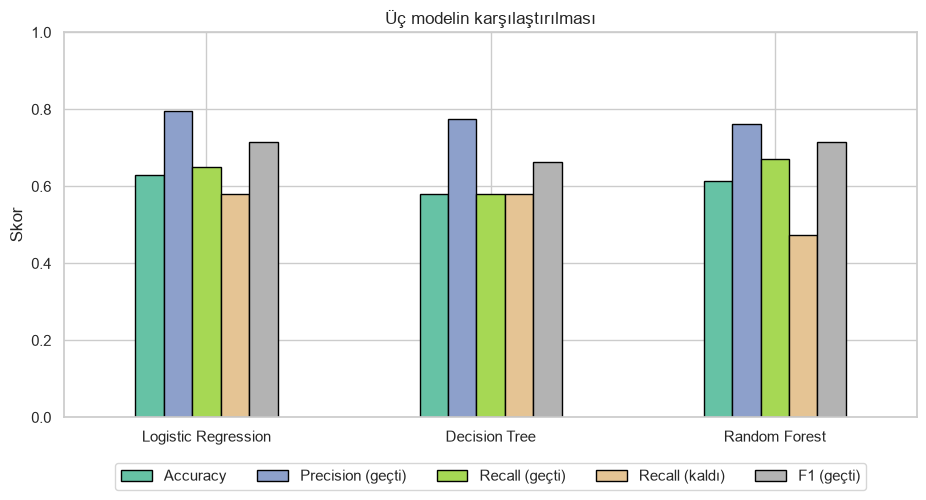

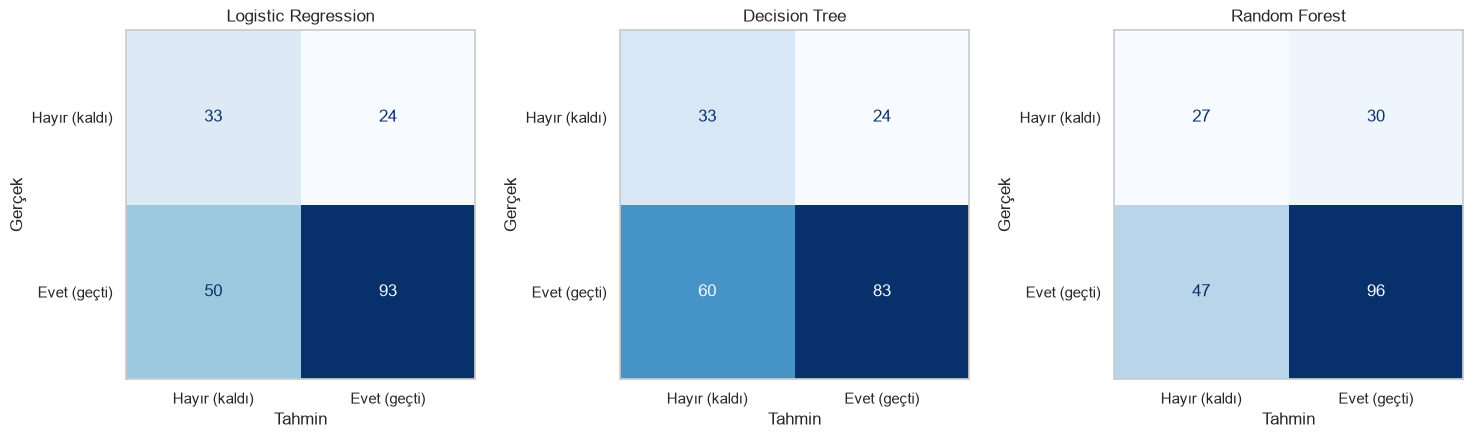

In [24]:
karsilastirma.plot(kind="bar", figsize=(11, 5), colormap="Set2", edgecolor="black")
plt.title("Üç modelin karşılaştırılması")
plt.ylabel("Skor")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=5)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (ad, p) in zip(axes, tahminler.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p),
                           display_labels=["Hayır (kaldı)", "Evet (geçti)"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(ad)
    ax.grid(False)
    ax.set_xlabel("Tahmin")
    ax.set_ylabel("Gerçek")
plt.tight_layout()
plt.show()

**Yorum:**
- **Random Forest**, accuracy'de (0.615) Decision Tree'yi (0.58) geçiyor ama Logistic Regression'ın (0.63) gerisinde kalıyor.
  Geçenleri yakalamada (recall 0.671) en iyisi olsa da **kalan öğrencilerin sadece %47.4'ünü** yakalayabiliyor. Diğer iki model %57.9 yakalıyor.
- Bu problemde en önemli metrik "kaldı" sınıfının recall'u (bkz. 5.4). Bu yüzden Random Forest daha karmaşık bir model olmasına rağmen
  bizim amacımız için daha kötü.
- **Kazanan: Logistic Regression.** Hem accuracy'si en yüksek, hem kalan öğrencileri en iyi yakalayan model (Decision Tree ile birlikte),
  hem de katsayıları sayesinde yorumlanması en kolay model.
- Neden karmaşık model daha iyi değil? Elimizde sadece 5 kategorik özellik var ve bunların etkisi büyük ölçüde **toplanabilir**
  (kurs + yemek + ebeveyn eğitimi...). Bu tip basit bir ilişkiyi en iyi doğrusal bir model olan Logistic Regression yakalıyor.
  Ağaç tabanlı modeller ise eğitim verisindeki gürültüyü de öğrenmeye daha yatkın.

### 6.2 Modelin yanlış tahmin ettiği örnekler

Ana modelimiz Logistic Regression'ın hatalarına bakıyoruz. Her öğrenci için modelin verdiği **geçme olasılığını** (`predict_proba`)
da gösteriyoruz. Olasılık 0.5'in üstündeyse model "geçer" diyor. Aşağıda, modelin **en emin olduğu halde yanıldığı** öğrenciler var.

In [25]:
lr = modeller["Logistic Regression"]
inceleme = df.loc[X_test.index, ["gender", "race/ethnicity", "parental level of education", "lunch",
                                 "test preparation course", "ortalama"]].copy()
inceleme["ortalama"] = inceleme["ortalama"].round(1)
inceleme["gerçek"] = y_test.map({1: "geçti", 0: "kaldı"})
inceleme["geçme olasılığı"] = lr.predict_proba(X_test)[:, 1].round(2)
inceleme["tahmin"] = pd.Series(tahminler["Logistic Regression"], index=X_test.index).map({1: "geçer", 0: "kalır"})

yanlis_evet = inceleme[(inceleme["gerçek"] == "kaldı") & (inceleme["tahmin"] == "geçer")]
yanlis_hayir = inceleme[(inceleme["gerçek"] == "geçti") & (inceleme["tahmin"] == "kalır")]
print(f"Yanlış 'evet' sayısı: {len(yanlis_evet)} | Yanlış 'hayır' sayısı: {len(yanlis_hayir)}")

Yanlış 'evet' sayısı: 24 | Yanlış 'hayır' sayısı: 50


#### a) Yanlış "evet": Gerçekte kaldı, ama model "geçer" dedi

In [26]:
yanlis_evet.sort_values("geçme olasılığı", ascending=False).head(3)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,ortalama,gerçek,geçme olasılığı,tahmin
174,female,group C,bachelor's degree,free/reduced,completed,49.3,kaldı,0.76,geçer
913,female,group C,bachelor's degree,free/reduced,completed,58.3,kaldı,0.76,geçer
153,male,group D,bachelor's degree,standard,none,50.0,kaldı,0.74,geçer


**Yorum:** Model bu üç öğrenciye %74–76 olasılıkla "geçer" dedi, çünkü üçünün de profili "geçer" profiline uyuyor:
- **174 ve 913 numaralı öğrenciler:** Kız, ebeveyni lisans mezunu ve **hazırlık kursunu tamamlamış**. Bunlar modelin en olumlu bulduğu özellikler.
  Tek olumsuz özellikleri ücretsiz/indirimli yemek. İkisinin bilgileri birebir aynı olduğu için model ikisine de aynı olasılığı verdi.
  913 numaralı öğrencinin ortalaması 58.3, yani eşiğin (60) çok yakınında. Neredeyse geçiyordu, model aslında büyük bir hata yapmadı.
- **153 numaralı öğrenci:** Kurs almamış ama standart yemek, ebeveyn lisans mezunu ve grup D. Bu güçlü olumlu özellikler kurs eksikliğini dengeledi.

**Neden yanıldı?** Bu öğrenciler kağıt üzerinde "başarılı öğrenci" profiline sahip ama yine de kaldılar. Model sadece arka plan bilgisini görüyor;
öğrencinin ne kadar çalıştığını, sınav günü hasta olup olmadığını, derse ilgisini **bilemez**. Aynı profildeki öğrencilerin çoğu geçtiği için
model bunlara da "geçer" dedi. Örneğin tüm veri setinde 174/913 ile birebir aynı profile sahip 6 öğrenci var ve bunların 4'ü geçmiş;
153 ile aynı profildeki 5 öğrencinin de 4'ü geçmiş. Bu, kalacak öğrenciyi gözden kaçıran, **en maliyetli hata türü** (5.4).

#### b) Yanlış "hayır": Gerçekte geçti, ama model "kalır" dedi

In [27]:
yanlis_hayir.sort_values("geçme olasılığı").head(3)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,ortalama,gerçek,geçme olasılığı,tahmin
228,male,group A,some high school,free/reduced,none,68.0,geçti,0.09,kalır
444,male,group A,some high school,free/reduced,none,78.0,geçti,0.09,kalır
699,male,group C,high school,free/reduced,none,63.7,geçti,0.12,kalır


**Yorum:** Bu öğrencilerde durum tam tersi. Model bunlara sadece %9–12 geçme olasılığı verdi, çünkü olumsuz özelliklerin **hepsini** taşıyorlar:
erkek, ebeveyni lise veya lise terk, ücretsiz/indirimli yemek ve **hazırlık kursu almamış**. 228 ve 444 numaralı öğrenciler ayrıca
en düşük geçme oranına sahip grup A'da.

Buna rağmen üçü de geçti. Özellikle **444 numaralı öğrencinin ortalaması 78**, tüm öğrencilerin ortalamasının (67.8) bile üstünde.
Veri setinde 228/444 ile birebir aynı profile sahip 5 öğrenci var: bunların 3'ü kalmış, 2'si geçmiş. Yani model bu profildeki
çoğunluğa göre karar verdi ve geçen azınlığı tahmin edemedi.
Bu öğrenciler "zor koşullara rağmen başarılı olan" öğrenciler. Model bireysel çabayı göremediği için onları grup ortalamasına göre değerlendirdi.

### Hata analizinden çıkan sonuç
1. **Aynı özelliklere sahip öğrenciler her zaman aynı tahmini alır** (174 ve 913, ya da 228 ve 444 gibi). Ama gerçekte aynı profildeki öğrencilerin
   bazıları geçer, bazıları kalır. Model ne kadar iyi olursa olsun bu 5 özellikle bu farkı ayırt edemez.
2. Hataların kaynağı modelin kendisinden çok **verinin eksikliği**: Çalışma süresi, devamsızlık, önceki notlar gibi öğrencinin kendi çabasını gösteren
   bilgiler olsaydı bu öğrenciler doğru tahmin edilebilirdi.
3. Eşiğe yakın öğrenciler (913 gibi, 58.3 ortalama) doğası gereği zor vakalardır; küçük bir not farkı sonucu değiştirir.

## Genel Sonuç

- Veri setinde 1000 öğrenci var, eksik değer yok. Ortalaması 60 ve üzeri olan öğrenciler "geçti" kabul edildi: **%71.5 geçti, %28.5 kaldı** (hafif dengesiz).
- Grafikler, geçmeyi en çok etkileyen faktörlerin **öğle yemeği türü (sosyoekonomik durum)**, **hazırlık kursu**, **ebeveyn eğitimi**, **cinsiyet** ve **etnik grup** olduğunu gösterdi.
- Sınav notlarını kullanmadan yalnızca bu arka plan bilgileriyle kurulan **Logistic Regression** modeli **%63 accuracy** elde etti ve
  kalacak öğrencilerin **%57.9'unu** doğru tespit etti. Decision Tree'den (%58 accuracy) ve Random Forest'tan (%61.5 accuracy, kalanların %47.4'ü) daha başarılı oldu.
- Hata analizi, modelin yanıldığı öğrencilerin "profilinin tersine" sonuç alan öğrenciler olduğunu gösterdi; model bireysel çabayı göremiyor.
- Bu problemde **yanlış "evet" (kalacak öğrenciye "geçer" demek) daha maliyetli** olduğu için model, kalan öğrencileri yakalamaya öncelik verecek şekilde ayarlandı.
- Arka plan bilgileri sonucu kısmen açıklıyor. Daha iyi tahmin için çalışma saati, devamsızlık, önceki dönem notları gibi ek bilgilere ihtiyaç var.

### Önemli not: Verinin sınırları
Bu veri seti gerçek öğrencilerden toplanmamıştır. Royce Kimmons'ın veri bilimi öğrencileri için hazırladığı bir **veri üreticisiyle
yapay (kurgusal) olarak oluşturulmuştur** (kaynak: roycekimmons.com/tools/generated_data/exams). Yani öğle yemeği, hazırlık kursu gibi özelliklerin notlara etkisi, veriyi
üreten araçta tanımlanmış olabilir. Modelimiz büyük ihtimalle bu tanımlanmış ilişkileri geri bulmaktadır.

Bu nedenle **buradaki sonuçlar gerçek öğrenciler için genellenemez.** Bu çalışma, gerçek bir eğitim politikasına dayanak olmaktan çok, bir sınıflandırma
probleminin uçtan uca nasıl kurulduğunu (veri tanıma → temizleme → görselleştirme → model → değerlendirme) göstermek amacıyla yapılmıştır.